# COS30082 Project – Part 1: Independent CNN models (disease category)

Three **independent** CNNs (ResNet-50, EfficientNet-B0, ConvNeXt-Tiny) are each fine-tuned to predict the **disease category** (175 classes) on DPD-Small. This is the companion of the crop notebook and uses the same backbones, so the two can be compared directly.

**Improvements over the crop notebook**
1. **Proper validation split.** A stratified 10% of the *training* set is held out for early stopping and best-model selection. The **seen test set is only used once, for the final evaluation**, so the seen numbers are no longer optimistic.
2. **Data augmentation** on the training set only (random resized crop, flips, rotation, colour jitter, random erasing). The crop notebook reached ~100% train accuracy within about 8 epochs, which is a clear sign of overfitting.
3. **Mixup/CutMix** (light, on half the batches) and label smoothing as extra regularisation.
4. **EMA of the weights** for smoother, more robust checkpoints.
5. **Longer schedule** (up to 40 epochs, patience 12), because augmented training converges more slowly.
6. **Diagnostics for unseen compositions:** reports how many unseen test images have a disease label that was seen in training, which is the upper bound for any disease classifier on the unseen set.

Evaluation on the *seen* and *unseen* test sets: **Top-1/3/5 accuracy**, **harmonic mean** `H = 2·S·U/(S+U)`, and **confusion matrices** (seen and unseen).

Set the runtime to **GPU** before running. Data: same shared Drive folder as the crop notebook (`DPD_Small_clean`).

In [1]:
!pip -q install timm

## 1. Configuration

In [2]:
import os, re, glob, json, time, random, shutil, copy
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
import timm
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

CFG = dict(
    drive_root    = "/content/drive/MyDrive",
    version       = "DPD_Small_clean",
    out_dir       = "/content/drive/MyDrive/DPD_runs/disease_independent",
    copy_local    = True,
    img_size      = 224,
    batch_size    = 64,
    epochs        = 30,
    patience      = 10,          # early stopping on the held-out validation split (Top-1)
    val_frac      = 0.10,        # stratified fraction of TRAIN held out for validation
    label_smooth  = 0.1,
    mix_prob      = 0.5,         # probability a batch uses Mixup/CutMix (0 disables)
    ema_decay     = 0.998,       # EMA of weights (0 disables)
    workers       = 2,
    seed          = 42,
    topk          = (1, 3, 5),
)
# model name -> (timm id, learning rate)
MODELS = {
    "ResNet50":        ("resnet50",        3e-4),
    "EfficientNet-B0": ("efficientnet_b0", 5e-4),
    "ConvNeXt-Tiny":   ("convnext_tiny",   1e-4),
}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

from google.colab import drive
drive.mount("/content/drive")
os.makedirs(CFG["out_dir"], exist_ok=True)

Device: cuda Tesla T4
Mounted at /content/drive


## 2. Locate the data (CSVs + images)

In [3]:
def find_dir(root, name, max_depth=5):
    root = root.rstrip("/")
    if os.path.basename(root) == name: return root
    for dp, dns, _ in os.walk(root, followlinks=True):
        if dp[len(root):].count("/") >= max_depth: dns[:] = []; continue
        if name in dns: return os.path.join(dp, name)
    return None

VER_ROOT = find_dir(CFG["drive_root"], CFG["version"])
if VER_ROOT is None:
    print("Top level of drive_root:", os.listdir(CFG["drive_root"])[:50])
    raise FileNotFoundError(f"Could not find '{CFG['version']}' under {CFG['drive_root']}. Add the shared folder as a shortcut to My Drive, "
                            "or set drive_root to the exact folder path.")
print("Version root:", VER_ROOT)

def norm(s): return re.sub(r"[\s\-]+", "_", s.lower())
csvs = glob.glob(os.path.join(VER_ROOT, "**", "*.csv"), recursive=True)
csv_map = {}
for p in csvs:
    n = norm(os.path.basename(p))
    if "unseen" in n:   csv_map["unseen"] = p
    elif "seen" in n:   csv_map["seen"] = p
    elif "train" in n:  csv_map["train"] = p
print(json.dumps(csv_map, indent=2))
assert set(csv_map) == {"train", "seen", "unseen"}, f"Could not find all 3 CSVs, found: {list(csv_map)}"

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
img_index = {}
for dp, _, fs in os.walk(VER_ROOT):
    for f in fs:
        if f.lower().endswith(IMG_EXT):
            img_index.setdefault(f, os.path.join(dp, f))
print("Images indexed:", len(img_index))

Version root: /content/drive/MyDrive/DPD_Small_clean
{
  "train": "/content/drive/MyDrive/DPD_Small_clean/train.csv",
  "seen": "/content/drive/MyDrive/DPD_Small_clean/test_seen.csv",
  "unseen": "/content/drive/MyDrive/DPD_Small_clean/test_unseen.csv"
}
Images indexed: 11443


In [4]:
def load_csv(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df.columns = [c.strip().lower() for c in df.columns]
    print(f"--- {os.path.basename(path)}  rows={len(df)}  columns={list(df.columns)}")
    need = {"path", "filename", "disease_id", "disease"}
    assert need <= set(df.columns), f"Missing columns {need - set(df.columns)}"
    df = df[df["disease_id"].str.strip().str.isdigit()]
    return pd.DataFrame({"path_csv": df["path"].str.strip(),
                         "image": df["filename"].str.strip(),
                         "disease": df["disease_id"].astype(int),
                         "disease_name": df["disease"].astype(str)}).reset_index(drop=True)

dfs = {k: load_csv(v) for k, v in csv_map.items()}

stem_index = {}
for f, p in img_index.items():
    stem_index.setdefault(os.path.splitext(f)[0].lower(), p)

def resolve(image, path_csv):
    names = (image, os.path.basename(path_csv))
    for n in names:
        if n in img_index: return img_index[n]
    for n in names:
        s = os.path.splitext(n)[0].lower()
        if s in stem_index: return stem_index[s]
    return None

for k, d in dfs.items():
    d["path"] = [resolve(i, p) for i, p in zip(d["image"], d["path_csv"])]
    ok = d["path"].notna()
    print(f"{k:7s}: {len(d)} rows, {(~ok).sum()} missing images dropped")
    dfs[k] = d[ok].reset_index(drop=True)

NUM_CLASSES = int(max(d["disease"].max() for d in dfs.values())) + 1
print("Disease classes:", NUM_CLASSES)
names = pd.concat(dfs.values()).drop_duplicates("disease").set_index("disease")["disease_name"].to_dict()
CLASS_NAMES = [names.get(i, str(i)) for i in range(NUM_CLASSES)]

if CFG["copy_local"]:
    LOCAL = "/content/dpd_local"; os.makedirs(LOCAL, exist_ok=True)
    allp = sorted({p for d in dfs.values() for p in d["path"]})
    def cp(p):
        dst = os.path.join(LOCAL, os.path.basename(p))
        if not os.path.exists(dst): shutil.copyfile(p, dst)
        return dst
    with ThreadPoolExecutor(16) as ex:
        new = dict(zip(allp, tqdm(ex.map(cp, allp), total=len(allp), desc="Copying images")))
    for d in dfs.values(): d["path"] = d["path"].map(new)

dfs["train"].head()

--- train.csv  rows=7200  columns=['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled']
--- test_seen.csv  rows=2000  columns=['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled']
--- test_unseen.csv  rows=1448  columns=['path', 'filename', 'crop_id', 'disease_id', 'comp_id', 'crop', 'disease', 'comp', 'source', 'flag_near_dup', 'flag_upscaled']
train  : 7200 rows, 0 missing images dropped
seen   : 2000 rows, 0 missing images dropped
unseen : 1448 rows, 0 missing images dropped
Disease classes: 175


Copying images:   0%|          | 0/10648 [00:00<?, ?it/s]

,path_csv,image,disease,disease_name,path
0,images/BLSD_banana_sigatoka_615.jpg,BLSD_banana_sigatoka_615.jpeg,26,sigatoka,/content/dpd_local/BLSD_banana_sigatoka_615.jpg
1,images/PD_paddy_bacterial_panicle_blight_1285.jpg,PD_paddy_bacterial_panicle_blight_1285.jpg,120,bacterial_panicle_blight,/content/dpd_local/PD_paddy_bacterial_panicle_...
2,images/PWV2_peach_leaf_curl_6128.jpg,PWV2_peach_leaf_curl_6128.jpg,57,curl,/content/dpd_local/PWV2_peach_leaf_curl_6128.jpg
3,images/CDC_cassava_mosaic_disease_4891.jpg,CDC_cassava_mosaic_disease_4891.jpg,51,mosaic,/content/dpd_local/CDC_cassava_mosaic_disease_...
4,images/CDDM_apple_cedar_apple_rust_11791.jpg,CDDM_apple_cedar_apple_rust_11791.jpg,5,cedar_apple_rust,/content/dpd_local/CDDM_apple_cedar_apple_rust...


## 3. Validation split and label diagnostics
A **stratified** 10% of the training images (per disease class) is held out as the validation set. Classes with a single training image stay in the training set. The seen test set is *not* used for any decision, and neither is the unseen test set.

In [5]:
def stratified_split(df, frac, seed):
    rng = np.random.RandomState(seed)
    val_idx = []
    for _, g in df.groupby("disease"):
        idx = g.index.to_numpy()
        if len(idx) < 2: continue
        n_val = max(1, int(round(len(idx) * frac)))
        val_idx += rng.choice(idx, n_val, replace=False).tolist()
    val = df.loc[sorted(val_idx)].reset_index(drop=True)
    tr  = df.drop(index=val_idx).reset_index(drop=True)
    return tr, val

df_train, df_val = stratified_split(dfs["train"], CFG["val_frac"], CFG["seed"])
df_seen, df_unseen = dfs["seen"], dfs["unseen"]
print(f"train={len(df_train)}  val={len(df_val)}  seen_test={len(df_seen)}  unseen_test={len(df_unseen)}")

# --- diagnostics
train_cls = set(df_train["disease"])
print("Disease classes present in training:", len(train_cls), "of", NUM_CLASSES)
for k, d in [("seen", df_seen), ("unseen", df_unseen)]:
    cov = d["disease"].isin(train_cls).mean() * 100
    print(f"{k:7s}: {cov:.1f}% of test images have a disease label that appears in training "
          f"(ceiling for any closed-set disease classifier on this split)")
print("Train images per disease: min", df_train["disease"].value_counts().min(),
      "median", int(df_train["disease"].value_counts().median()),
      "max", df_train["disease"].value_counts().max())

train=6439  val=761  seen_test=2000  unseen_test=1448
Disease classes present in training: 175 of 175
seen   : 100.0% of test images have a disease label that appears in training (ceiling for any closed-set disease classifier on this split)
unseen : 100.0% of test images have a disease label that appears in training (ceiling for any closed-set disease classifier on this split)
Train images per disease: min 1 median 8 max 1288


## 4. Datasets and loaders (with augmentation)
Augmentation is applied to the **training** images only. Validation and test images are only resized (a no-op for 224×224 images) and normalised.

{'train': 6439, 'val': 761, 'seen_test': 2000, 'unseen_test': 1448}


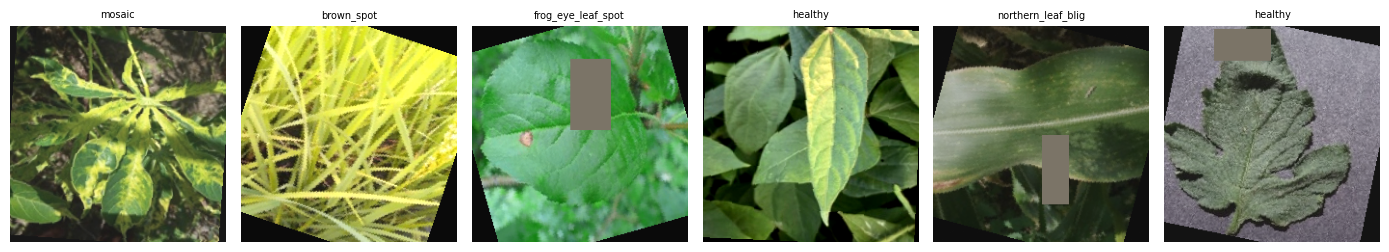

In [10]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
S = CFG["img_size"]
tf_train = T.Compose([
    T.RandomResizedCrop(S, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(25),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    T.ToTensor(), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25),
])
tf_eval = T.Compose([T.Resize((S, S)), T.ToTensor(), T.Normalize(MEAN, STD)])

class DiseaseDS(Dataset):
    def __init__(self, df, tf): self.p, self.y, self.tf = df["path"].tolist(), df["disease"].tolist(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def mk(df, tf, shuffle):
    return DataLoader(DiseaseDS(df, tf), batch_size=CFG["batch_size"], shuffle=shuffle,
                      num_workers=CFG["workers"], pin_memory=True, drop_last=shuffle,
                      persistent_workers=CFG["workers"] > 0)
dl_train  = mk(df_train,  tf_train, True)
dl_val    = mk(df_val,    tf_eval,  False)   # validation: early stopping + model selection
dl_seen   = mk(df_seen,   tf_eval,  False)   # final evaluation only
dl_unseen = mk(df_unseen, tf_eval,  False)   # final evaluation only
print({k: len(v.dataset) for k, v in dict(train=dl_train, val=dl_val, seen_test=dl_seen, unseen_test=dl_unseen).items()})

# quick look at augmentations
x, y = next(iter(dl_train))
fig, ax = plt.subplots(1, 6, figsize=(14, 2.6))
for i, a in enumerate(ax):
    im = (x[i] * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
    a.imshow(im.permute(1, 2, 0)); a.set_title(CLASS_NAMES[y[i]][:18], fontsize=7); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Training and evaluation helpers

In [11]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); outs, ys = [], []
    for x, y in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            o = model(x.to(DEVICE, non_blocking=True))
        outs.append(o.float().cpu()); ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def topk_acc(logits, y, ks=CFG["topk"]):
    top = logits.topk(max(ks), 1).indices
    hit = top.eq(y[:, None])
    return {k: hit[:, :k].any(1).float().mean().item() * 100 for k in ks}

def harmonic(s, u): return 0.0 if (s + u) == 0 else 2 * s * u / (s + u)

def mix_batch(x, y):
    """Mixup or CutMix (50/50). Returns mixed x, (y_a, y_b), lam."""
    idx = torch.randperm(x.size(0), device=x.device)
    if random.random() < 0.5:                                   # mixup
        lam = float(np.random.beta(0.4, 0.4))
        x = lam * x + (1 - lam) * x[idx]
    else:                                                       # cutmix
        lam = float(np.random.beta(1.0, 1.0))
        H, W = x.shape[2:]
        r = np.sqrt(1 - lam); h, w = int(H * r), int(W * r)
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2, x1, x2 = max(cy - h // 2, 0), min(cy + h // 2, H), max(cx - w // 2, 0), min(cx + w // 2, W)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, (y, y[idx]), lam

class EMA:
    def __init__(self, model, decay):
        self.m = copy.deepcopy(model).eval(); self.d = decay
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        for e, p in zip(self.m.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(self.d).add_(p.detach(), alpha=1 - self.d)
            else: e.copy_(p)

def train_model(name, timm_id, lr):
    seed_all(CFG["seed"])
    model = timm.create_model(timm_id, pretrained=True, num_classes=NUM_CLASSES).to(DEVICE)
    ema = EMA(model, CFG["ema_decay"]) if CFG["ema_decay"] > 0 else None
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    steps = CFG["epochs"] * len(dl_train)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smooth"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, best_ep, best_state, hist, bad = -1, 0, None, [], 0
    for ep in range(CFG["epochs"]):
        model.train(); tl, tc, n = 0.0, 0, 0; t0 = time.time()
        for x, y in tqdm(dl_train, desc=f"{name} ep{ep+1}/{CFG['epochs']}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            mixed = CFG["mix_prob"] > 0 and random.random() < CFG["mix_prob"]
            if mixed: x, (ya, yb), lam = mix_batch(x, y)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
                loss = lam * crit(out, ya) + (1 - lam) * crit(out, yb) if mixed else crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            if ema is not None: ema.update(model)
            tl += loss.item() * len(y); n += len(y)
            if not mixed: tc += (out.argmax(1) == y).sum().item()
        # train accuracy is tracked on un-mixed batches only; we also report loss over all batches
        eval_model = ema.m if ema is not None else model
        lg, yy = predict(eval_model, dl_val)
        va = topk_acc(lg, yy)[1]
        vl = nn.functional.cross_entropy(lg, yy).item()
        hist.append(dict(epoch=ep + 1, train_loss=tl / n, train_acc=np.nan, val_loss=vl, val_acc=va))
        print(f"[{name}] ep {ep+1:02d} | train loss {tl/n:.4f} | val loss {vl:.4f} acc {va:.2f} | {time.time()-t0:.0f}s")
        if va > best:
            best, best_ep, bad = va, ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in eval_model.state_dict().items()}
            torch.save({"state_dict": best_state, "timm_id": timm_id, "num_classes": NUM_CLASSES,
                        "class_names": CLASS_NAMES, "epoch": best_ep, "val_top1": best},
                       os.path.join(CFG["out_dir"], f"{name}_best.pt"))
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"[{name}] early stopping at epoch {ep+1} (best epoch {best_ep}, val acc {best:.2f})")
                break
    final = timm.create_model(timm_id, pretrained=False, num_classes=NUM_CLASSES).to(DEVICE)
    final.load_state_dict(best_state)
    print(f"[{name}] best model: epoch {best_ep}, val Top-1 {best:.2f} -> {CFG['out_dir']}/{name}_best.pt")
    return final, pd.DataFrame(hist), best_ep

@torch.no_grad()
def clean_train_acc(model, df):
    """Train accuracy measured without augmentation (clean, comparable to val acc)."""
    dl = mk(df, tf_eval, False)
    lg, yy = predict(model, dl)
    return topk_acc(lg, yy)[1]

def plot_curves(name, h, best_ep):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(h["epoch"], h["val_acc"], label="Validation accuracy (held-out train split)")
    ax[0].axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
    ax[0].set_title(f"{name}: validation accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy (%)")
    ax[1].plot(h["epoch"], h["train_loss"], label="Training loss (augmented/mixed)")
    ax[1].plot(h["epoch"], h["val_loss"], label="Validation loss")
    ax[1].axvline(best_ep, ls="--", c="gray")
    ax[1].set_title(f"{name}: loss"); ax[1].set_xlabel("Epoch")
    for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(CFG["out_dir"], f"{name}_curves.png"), dpi=150); plt.show()

def plot_cm(cm, title, path):
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title); ax.set_xlabel("Predicted disease id"); ax.set_ylabel("True disease id")
    fig.colorbar(im, ax=ax, fraction=0.046, label="Row-normalised rate")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

## 6. Train and evaluate the three independent models


===== ResNet50 (resnet50) =====


ResNet50 ep1/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ResNet50] ep 01 | train loss 5.0367 | val loss 5.1559 acc 0.79 | 59s


ResNet50 ep2/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ResNet50] ep 02 | train loss 4.1549 | val loss 5.0536 acc 6.04 | 59s


ResNet50 ep3/30:   0%|          | 0/100 [00:00<?, ?it/s]

... (51 outputs left out)

ResNet50 ep29/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ResNet50] ep 29 | train loss 1.6820 | val loss 1.0699 acc 73.72 | 54s


ResNet50 ep30/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ResNet50] ep 30 | train loss 1.5522 | val loss 1.0674 acc 73.59 | 54s
[ResNet50] best model: epoch 22, val Top-1 73.85 -> /content/drive/MyDrive/DPD_runs/disease_independent/ResNet50_best.pt


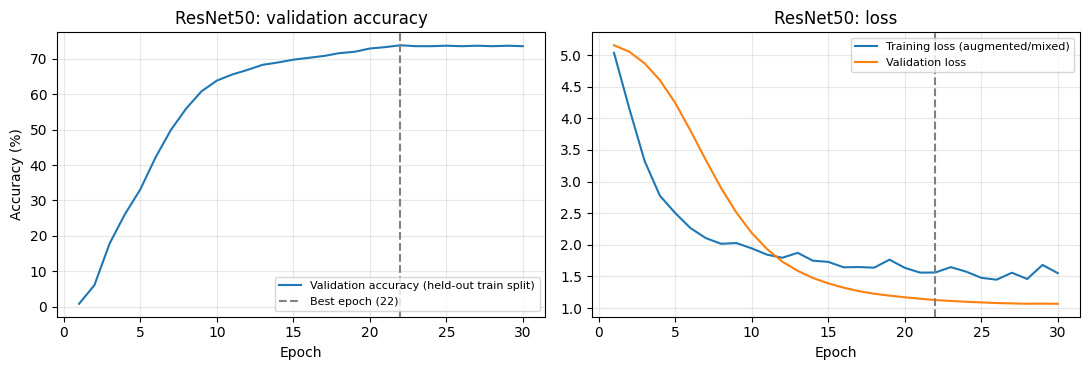

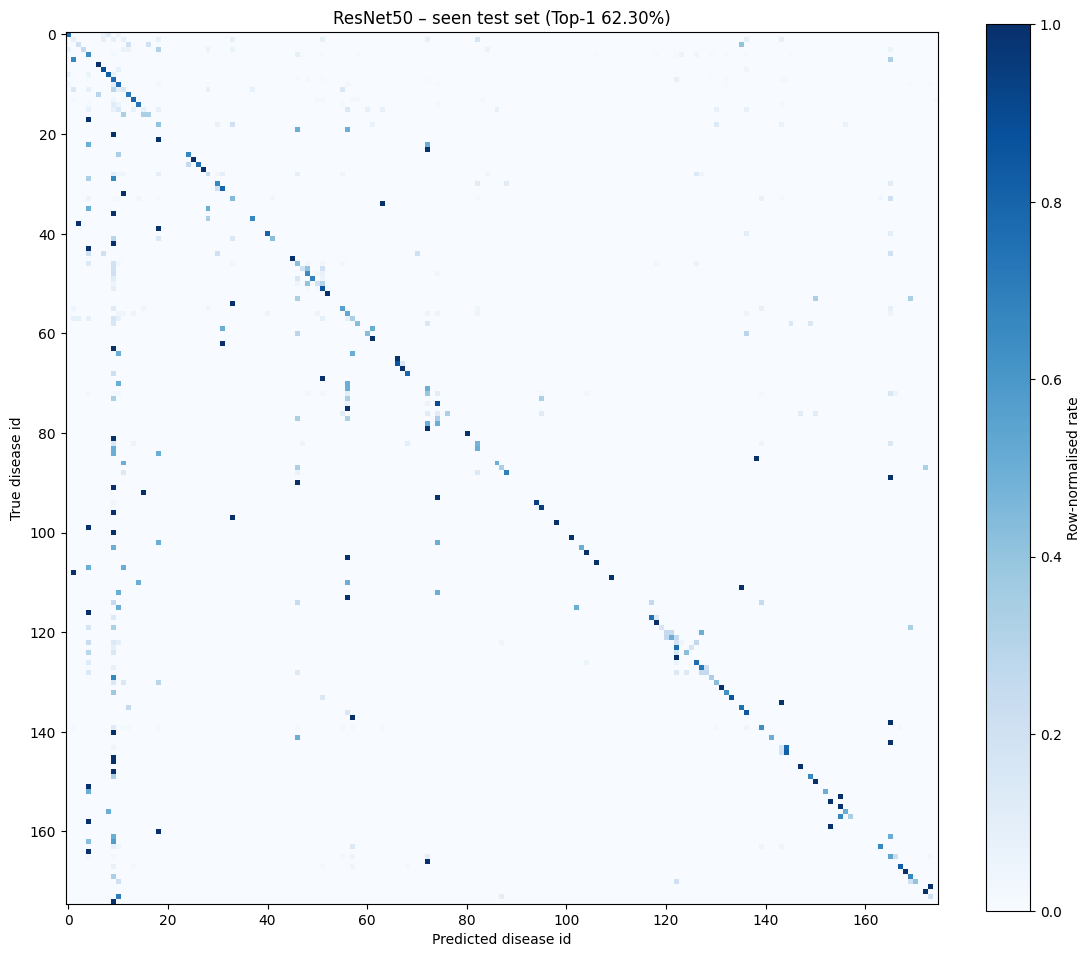

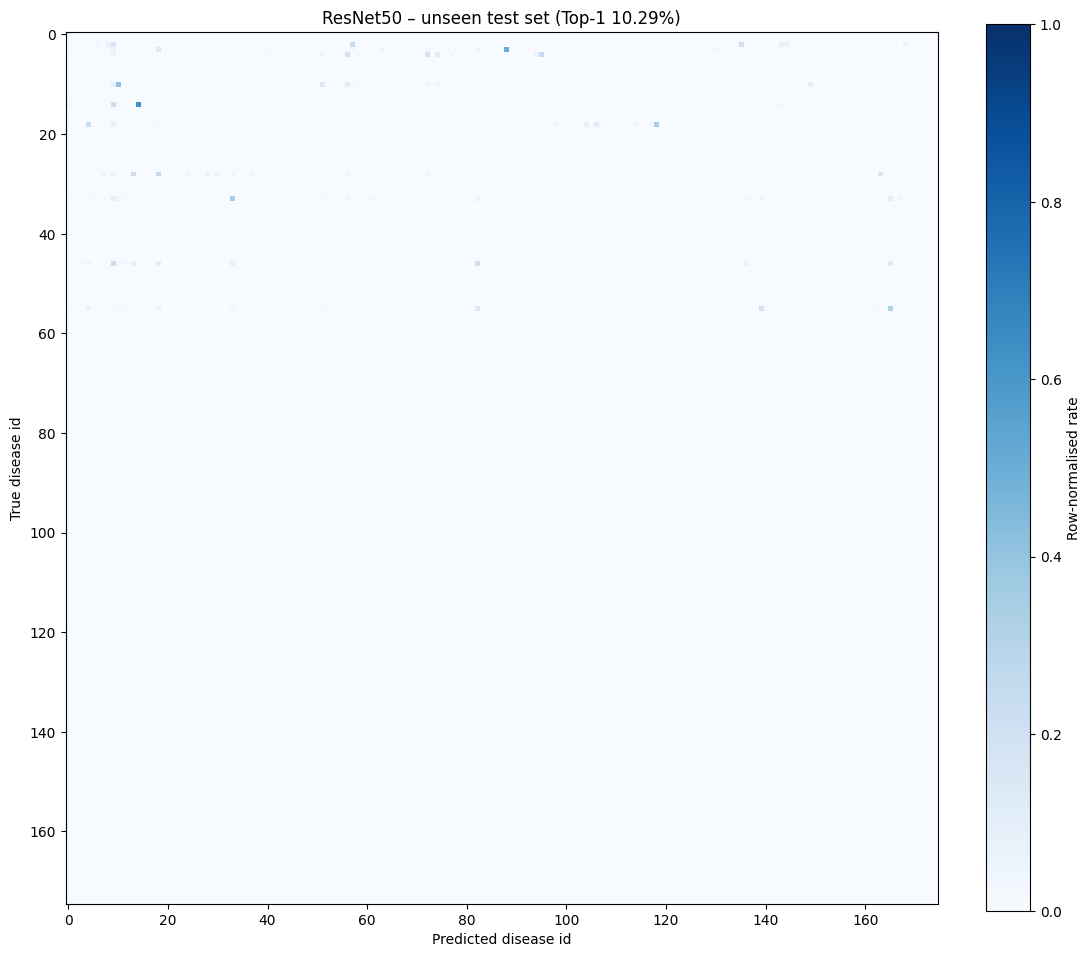

{
  "best_epoch": 22,
  "epochs_run": 30,
  "train_clean_top1": 92.9647445678711,
  "val": {
    "1": 73.85019659996033,
    "3": 88.1734549999237,
    "5": 91.72142148017883
  },
  "seen": {
    "1": 62.300002574920654,
    "3": 79.94999885559082,
    "5": 86.00000143051147
  },
  "unseen": {
    "1": 10.290054976940155,
    "3": 21.892264485359192,
    "5": 30.662983655929565
  },
  "harmonic": {
    "1": 17.662761903761936,
    "3": 34.37249847229155,
    "5": 45.207426096971616
  }
}

===== EfficientNet-B0 (efficientnet_b0) =====


EfficientNet-B0 ep1/30:   0%|          | 0/100 [00:00<?, ?it/s]

[EfficientNet-B0] ep 01 | train loss 4.7495 | val loss 5.3514 acc 0.26 | 52s


EfficientNet-B0 ep2/30:   0%|          | 0/100 [00:00<?, ?it/s]

[EfficientNet-B0] ep 02 | train loss 3.0796 | val loss 4.9016 acc 4.20 | 53s


EfficientNet-B0 ep3/30:   0%|          | 0/100 [00:00<?, ?it/s]

... (51 outputs left out)

EfficientNet-B0 ep29/30:   0%|          | 0/100 [00:00<?, ?it/s]

[EfficientNet-B0] ep 29 | train loss 1.5455 | val loss 1.0276 acc 78.84 | 55s


EfficientNet-B0 ep30/30:   0%|          | 0/100 [00:00<?, ?it/s]

[EfficientNet-B0] ep 30 | train loss 1.4093 | val loss 1.0302 acc 78.45 | 55s
[EfficientNet-B0] early stopping at epoch 30 (best epoch 20, val acc 79.24)
[EfficientNet-B0] best model: epoch 20, val Top-1 79.24 -> /content/drive/MyDrive/DPD_runs/disease_independent/EfficientNet-B0_best.pt


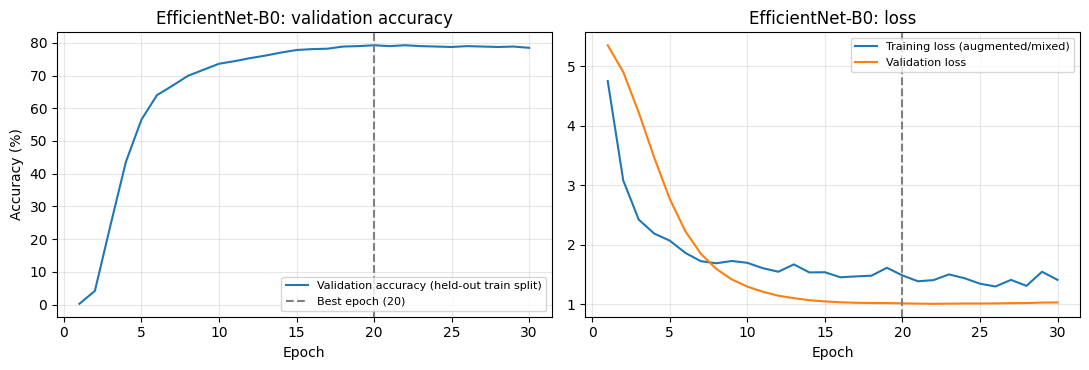

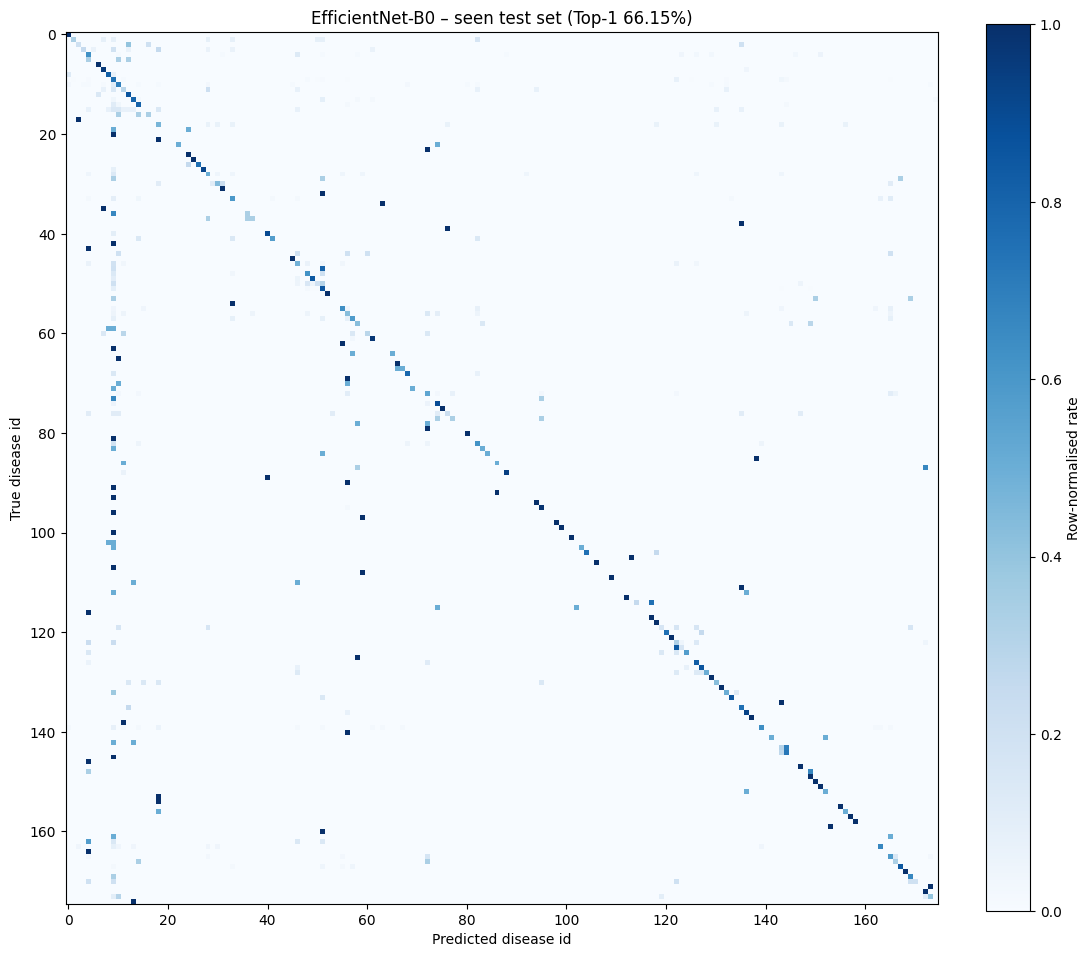

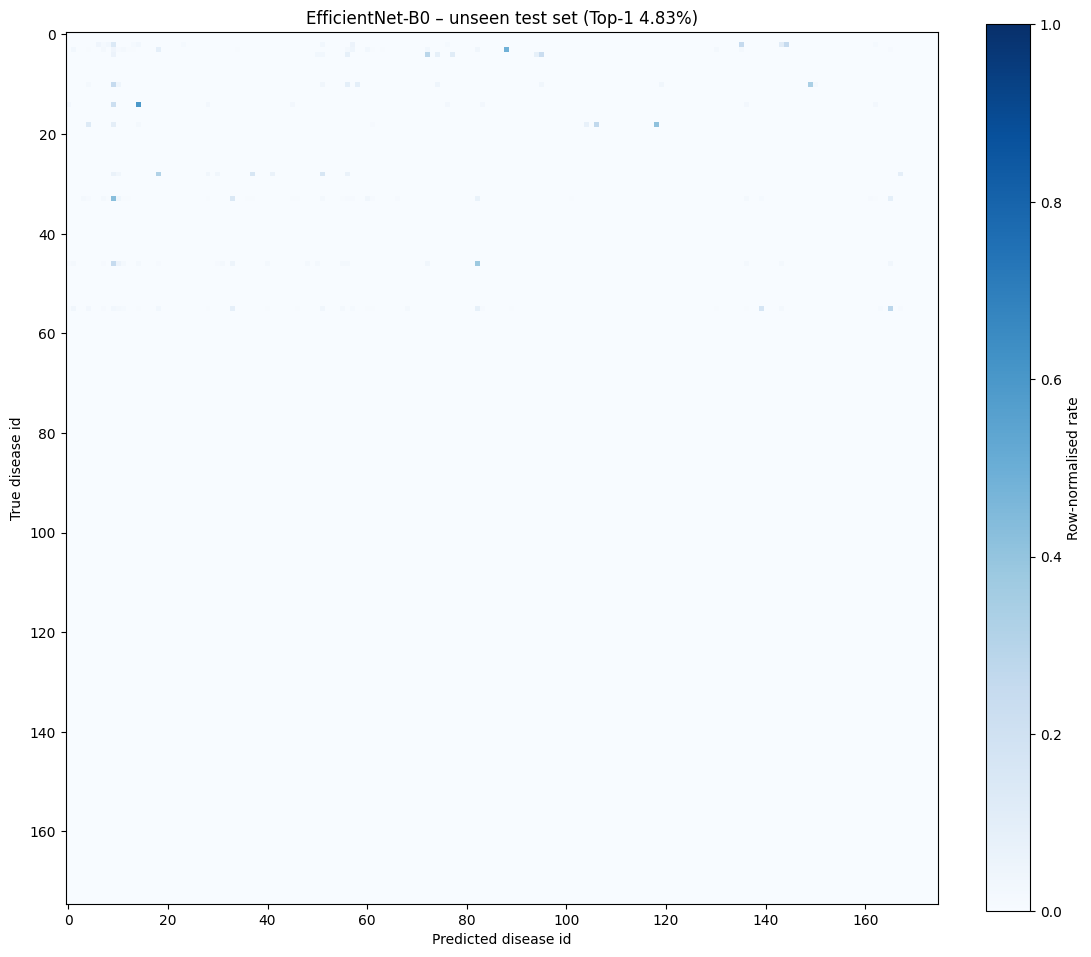

{
  "best_epoch": 20,
  "epochs_run": 30,
  "train_clean_top1": 99.58068132400513,
  "val": {
    "1": 79.23784255981445,
    "3": 89.61892127990723,
    "5": 92.7726686000824
  },
  "seen": {
    "1": 66.14999771118164,
    "3": 81.80000185966492,
    "5": 87.1500015258789
  },
  "unseen": {
    "1": 4.834254086017609,
    "3": 15.262430906295776,
    "5": 25.276243686676025
  },
  "harmonic": {
    "1": 9.010051909512491,
    "3": 25.725027509424486,
    "5": 39.18701850617897
  }
}

===== ConvNeXt-Tiny (convnext_tiny) =====


ConvNeXt-Tiny ep1/30:   0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_744/4194140737.py:63: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


[ConvNeXt-Tiny] ep 01 | train loss 4.1719 | val loss 5.1577 acc 3.15 | 57s


ConvNeXt-Tiny ep2/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ConvNeXt-Tiny] ep 02 | train loss 2.7649 | val loss 4.4507 acc 16.03 | 59s


... (50 outputs left out)

ConvNeXt-Tiny ep28/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ConvNeXt-Tiny] ep 28 | train loss 1.1473 | val loss 0.8366 acc 80.55 | 57s


ConvNeXt-Tiny ep29/30:   0%|          | 0/100 [00:00<?, ?it/s]

[ConvNeXt-Tiny] ep 29 | train loss 1.3150 | val loss 0.8395 acc 80.55 | 57s
[ConvNeXt-Tiny] early stopping at epoch 29 (best epoch 19, val acc 81.21)
[ConvNeXt-Tiny] best model: epoch 19, val Top-1 81.21 -> /content/drive/MyDrive/DPD_runs/disease_independent/ConvNeXt-Tiny_best.pt


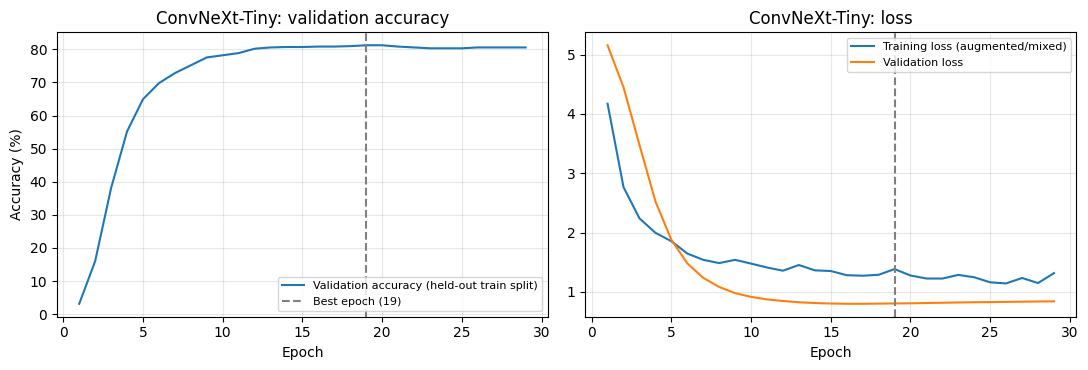

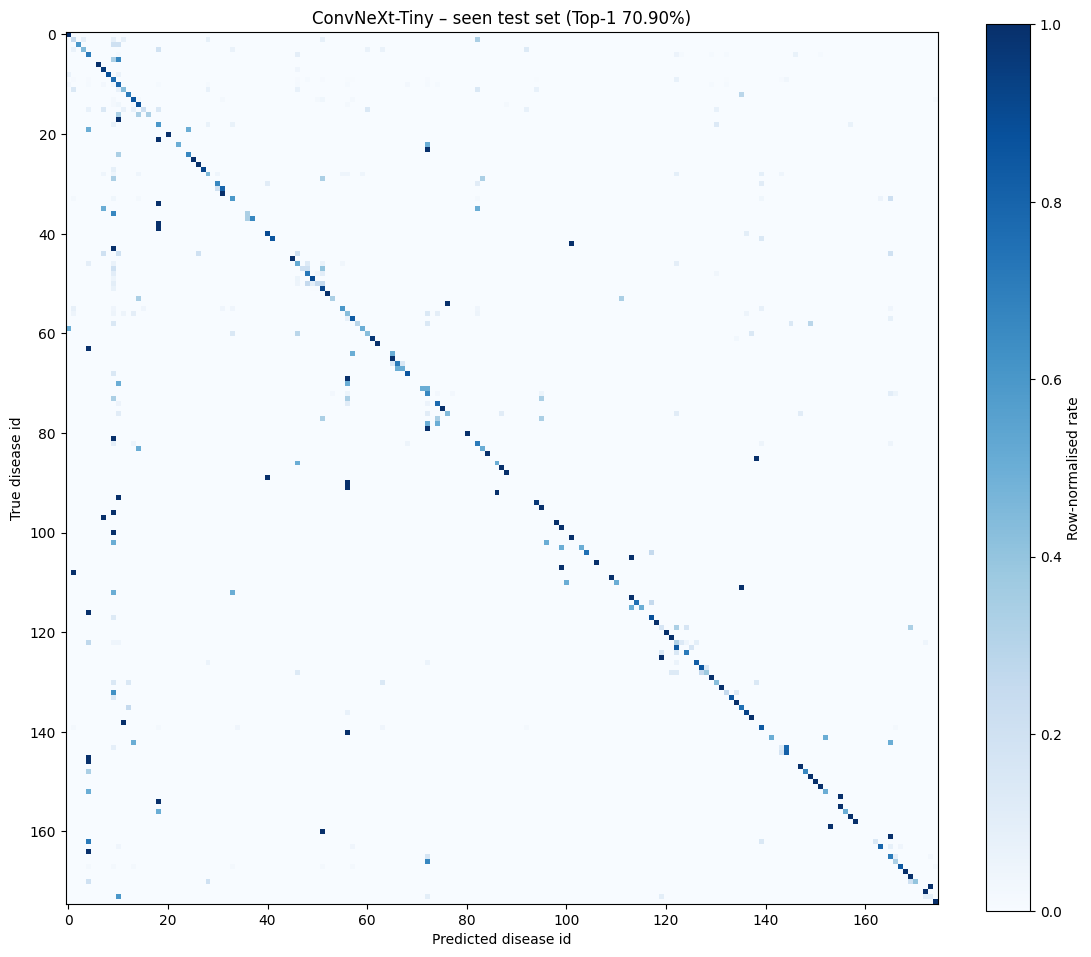

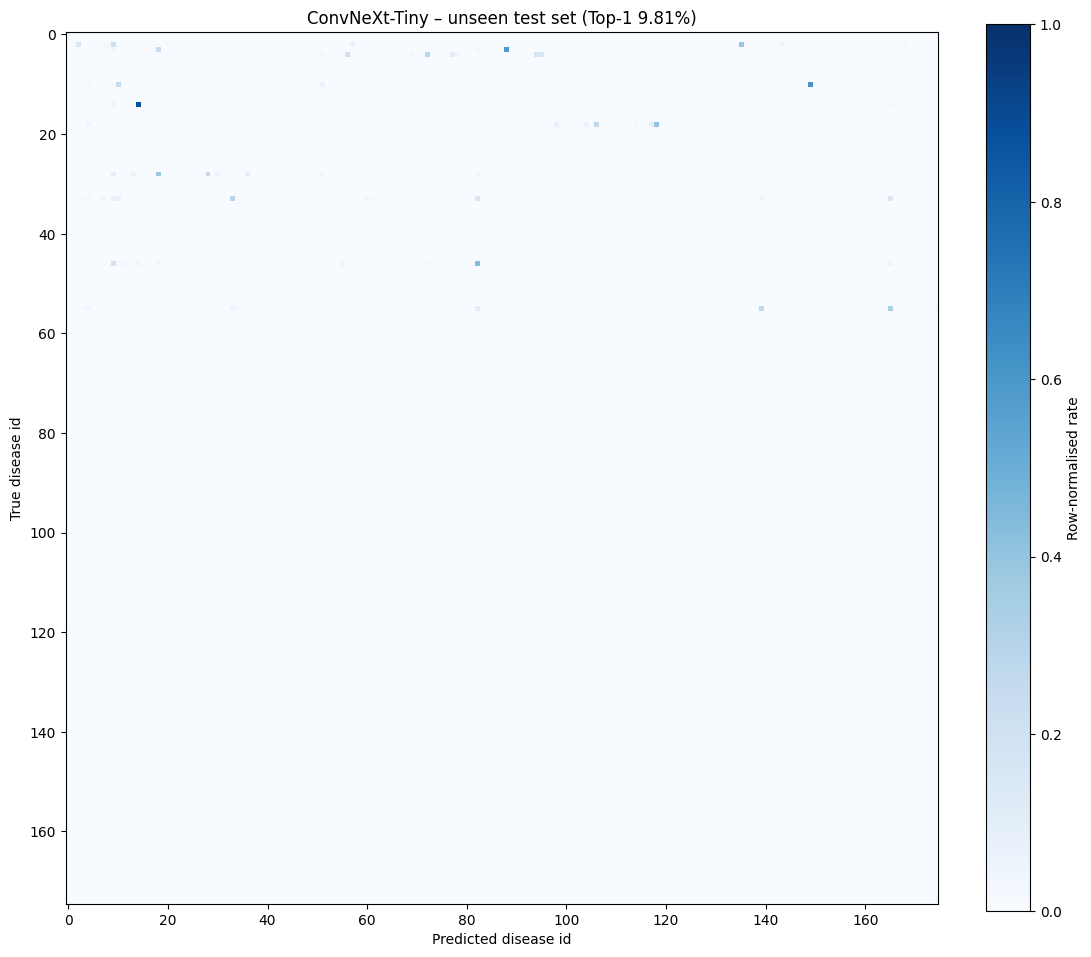

{
  "best_epoch": 19,
  "epochs_run": 29,
  "train_clean_top1": 99.64280128479004,
  "val": {
    "1": 81.20893836021423,
    "3": 93.16688776016235,
    "5": 95.40078639984131
  },
  "seen": {
    "1": 70.89999914169312,
    "3": 86.04999780654907,
    "5": 89.89999890327454
  },
  "unseen": {
    "1": 9.80663001537323,
    "3": 22.030386328697205,
    "5": 30.04143536090851
  },
  "harmonic": {
    "1": 17.230060700955125,
    "3": 35.0797179419648,
    "5": 45.03406220822489
  }
}


In [12]:
results, curves, cms = {}, {}, {}
for name, (tid, lr) in MODELS.items():
    print(f"\n===== {name} ({tid}) =====")
    model, hist, best_ep = train_model(name, tid, lr)
    curves[name] = hist
    hist.to_csv(os.path.join(CFG["out_dir"], f"{name}_history.csv"), index=False)
    plot_curves(name, hist, best_ep)
    r = {"best_epoch": best_ep, "epochs_run": len(hist)}
    r["train_clean_top1"] = clean_train_acc(model, df_train)
    lg, yy = predict(model, dl_val); r["val"] = topk_acc(lg, yy)
    for split, dl in [("seen", dl_seen), ("unseen", dl_unseen)]:
        lg, yy = predict(model, dl)
        acc = topk_acc(lg, yy)
        r[split] = acc
        cm = confusion_matrix(yy.numpy(), lg.argmax(1).numpy(), labels=list(range(NUM_CLASSES)))
        cms[(name, split)] = cm
        pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            os.path.join(CFG["out_dir"], f"{name}_{split}_confusion_matrix.csv"))
        plot_cm(cm, f"{name} – {split} test set (Top-1 {acc[1]:.2f}%)",
                os.path.join(CFG["out_dir"], f"{name}_{split}_confusion_matrix.png"))
    r["harmonic"] = {k: harmonic(r["seen"][k], r["unseen"][k]) for k in CFG["topk"]}
    results[name] = r
    print(json.dumps(r, indent=2))
    del model; torch.cuda.empty_cache()

json.dump(results, open(os.path.join(CFG["out_dir"], "results.json"), "w"), indent=2)

## 7. Summary

,Train(clean) Top-1,Val Top-1,Seen Top-1,Unseen Top-1,H Top-1,Seen Top-3,Unseen Top-3,H Top-3,Seen Top-5,Unseen Top-5,H Top-5
Model,,,,,,,,,,,
ResNet50,92.96,73.85,62.30,10.29,17.66,79.95,21.89,34.37,86.00,30.66,45.21
EfficientNet-B0,99.58,79.24,66.15,4.83,9.01,81.80,15.26,25.73,87.15,25.28,39.19
ConvNeXt-Tiny,99.64,81.21,70.90,9.81,17.23,86.05,22.03,35.08,89.90,30.04,45.03


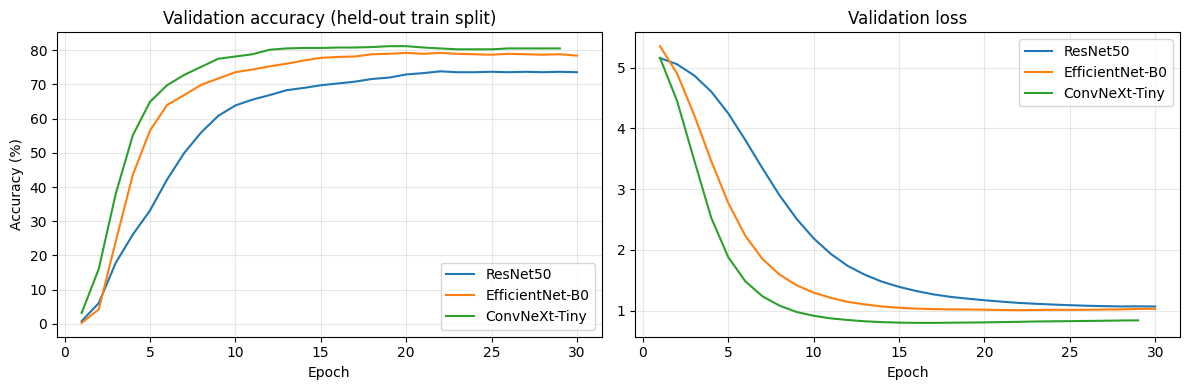

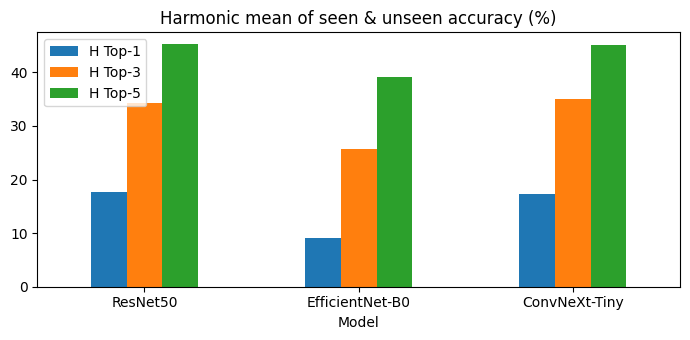

In [13]:
rows = []
for name, r in results.items():
    row = {"Model": name, "Train(clean) Top-1": r["train_clean_top1"], "Val Top-1": r["val"][1]}
    for k in CFG["topk"]:
        row[f"Seen Top-{k}"] = r["seen"][k]
        row[f"Unseen Top-{k}"] = r["unseen"][k]
        row[f"H Top-{k}"] = r["harmonic"][k]
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Model").round(2)
summary.to_csv(os.path.join(CFG["out_dir"], "summary.csv"))
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in curves.items():
    l, = ax[0].plot(h["epoch"], h["val_acc"], label=name)
    ax[1].plot(h["epoch"], h["val_loss"], label=name, color=l.get_color())
ax[0].set_title("Validation accuracy (held-out train split)"); ax[1].set_title("Validation loss")
for a in ax: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("Accuracy (%)")
fig.tight_layout(); fig.savefig(os.path.join(CFG["out_dir"], "all_models_val.png"), dpi=150); plt.show()

summary[[f"H Top-{k}" for k in CFG["topk"]]].plot.bar(figsize=(7, 3.5), rot=0, title="Harmonic mean of seen & unseen accuracy (%)")
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "harmonic_mean.png"), dpi=150); plt.show()

### Notes for the report
- **Validation protocol:** early stopping and model selection use a stratified 10% split of the *training* set. The seen and unseen test sets are evaluated once, after training, so both are clean estimates.
- **Regularisation:** augmentation (random resized crop, flips, rotation, colour jitter, random erasing), Mixup/CutMix, label smoothing, weight decay and EMA weights. The EMA weights are the ones evaluated and saved.
- **Training accuracy** is reported on the un-augmented training images after training (`Train(clean) Top-1`), so it is directly comparable with validation accuracy. During training only the loss is logged, because augmented/mixed batches make running accuracy misleading.
- **Unseen compositions:** unseen images are new crop–disease pairs. If a disease label in the unseen set never appears in training, a closed-set classifier can never predict it. The label-coverage diagnostic in section 3 gives the ceiling for unseen accuracy.
- **Harmonic mean** `H = 2SU/(S+U)` penalises models that do well on seen data but poorly on unseen data.
- Confusion matrices are row-normalised (diagonal = per-class recall). Raw counts are saved as CSV because 175 classes are too many to label on the plot.
- To compare with the crop notebook, report the same metrics side by side. The crop notebook used the seen test set for model selection, so part of any improvement here comes from the more honest protocol, not only from the augmentation.